# 01. Dataset Exploration and Feature Analysis

## Purpose
This notebook explores the training and validation dataset of the ACPDAD (Airborne Cyber-Physical Drone Attack Detection) project. It provides an in-depth analysis of the five flight classes, data layout, feature groups, class balance, missing values, and selected feature distributions.

> **Research Scope and Provenance Notice**  
> All data analyzed in this notebook is **purely simulated UAV telemetry** generated under controlled synthetic dynamics. It is not physical-drone telemetry, real radio transmission, captured Wi-Fi traffic, or ArduPilot SITL flight data.  
> In adherence to strict research integrity protocols, **only training and validation data (`data/train_validation/`) are explored here**. The frozen test dataset (`data/frozen_test/`) is strictly sequestered to avoid data snooping or leakage.

## The Five Classes
ACPDAD evaluates five distinct operational and adversarial flight classes:
1. **`Benign`**: Normal UAV flight execution subject to natural wind turbulence and background network traffic.
2. **`DoS` (Denial of Service)**: Network disruption where telemetry frames are dropped, delayed, or lost, resulting in inter-packet gaps.
3. **`Replay`**: Replay attacks where earlier legitimate telemetry frames are injected, preserving original source timestamps and sequence numbers.
4. **`Evil_Twin`**: Malicious Rogue Access Point attacks where unauthorized AP beaconing induces roaming handoffs and altered network metadata.
5. **`FDI` (False Data Injection)**: Sensor/state tampering that modifies kinematic telemetry (e.g., altitude, velocity coordinates) while flight dynamics continue.

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure relative paths from project root
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
os.chdir(ROOT)

DATA_DIR = Path('data/train_validation')

# Load dataset metadata and schema
with open(DATA_DIR / 'schema.json') as f:
    schema = json.load(f)

with open(DATA_DIR / 'experiment_config.json') as f:
    config = json.load(f)

print("Dataset: Training and Validation (Simulated Telemetry)")
print(f"Sampling Cadence: {config.get('sampling_hz')} Hz ({1.0/config.get('sampling_hz'):.2f}s per observation)")
print(f"Mission Duration: {config.get('duration_s')}s per flight run")
print(f"Base Features Count: {schema.get('base_count')}")
print(f"Temporal Features Count: {schema.get('temporal_count')}")
print(f"Configured Classes: {schema.get('classes')}")

Dataset: Training and Validation (Simulated Telemetry)
Sampling Cadence: 5 Hz (0.20s per observation)
Mission Duration: 60s per flight run
Base Features Count: 22
Temporal Features Count: 88
Configured Classes: ['Benign', 'DoS', 'Replay', 'Evil_Twin', 'FDI']

## Data Layout & Table Architecture
The training and validation dataset (`data/train_validation/`) is structured as a relational suite of tables linked by `run_id` and `observation_id`:
- **`run_manifest.csv`**: Run-level metadata (split, scenario, seed, flight profile, attack timing).
- **`ground_truth.csv`**: Observation-level ground truth (`Target_Label`, delivery indicator, active attack flag).
- **`features.csv`**: Delivered observation feature vectors (22 base features + 88 temporal features).
- **`delivered_packets.csv`**: Low-level packet reception timestamps, payload digests, and sequence numbers.
- **`emitted_packets.csv`**: Packets emitted by the vehicle before channel effects.
- **`true_state.csv`**: High-cadence physical ground truth of the UAV kinematics.
- **`network_flow.csv`**: Network transmission telemetry (latencies, channel handoffs, drops).

In [2]:
manifest = pd.read_csv(DATA_DIR / 'run_manifest.csv')
truth = pd.read_csv(DATA_DIR / 'ground_truth.csv')

print(f"Total Flight Runs: {len(manifest)}")
print(f"Runs by Split:\n{manifest['split'].value_counts()}\n")
print(f"Runs by Scenario:\n{manifest['scenario'].value_counts()}\n")
print(f"Observation Records in Ground Truth: {len(truth)}")

Total Flight Runs: 300
Runs by Split:
split
train    200
val      100
Name: count, dtype: int64

Runs by Scenario:
scenario
Benign       60
DoS          60
Replay       60
Evil_Twin    60
FDI          60
Name: count, dtype: int64

Observation Records in Ground Truth: 90000

## Class Balance Analysis
Let us inspect the distribution of classes across runs and scheduled timeline observations for both the training (`train`) and validation (`val`) splits.

Observation-Level Class Distribution across Splits:
Target_Label  Benign   DoS  Evil_Twin   FDI  Replay
split                                              
train          39451  5035       5367  4887    5260
val            19536  2647       2586  2649    2582
<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

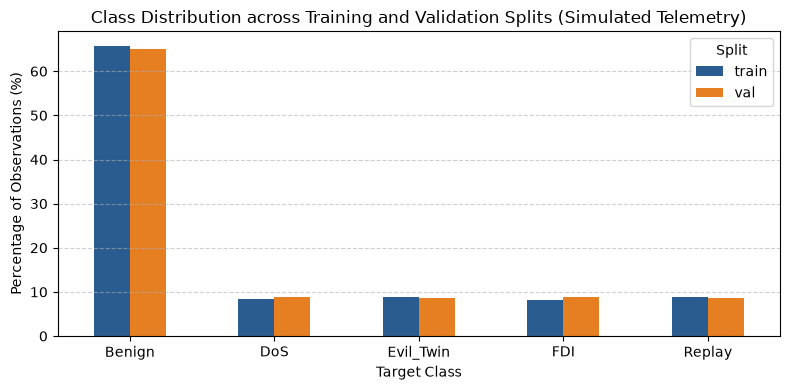

In [3]:
# Join truth with run manifest to analyze split distributions
truth_with_split = truth.merge(manifest[['run_id', 'split', 'scenario']], on='run_id', how='left')

split_class_counts = pd.crosstab(truth_with_split['split'], truth_with_split['Target_Label'])
print("Observation-Level Class Distribution across Splits:")
print(split_class_counts)

# Calculate percentage within each split
split_class_pct = split_class_counts.div(split_class_counts.sum(axis=1), axis=0) * 100

# Visualize Class Balance
fig, ax = plt.subplots(figsize=(8, 4))
split_class_pct.T.plot(kind='bar', ax=ax, color=['#2b5c8f', '#e67e22'])
ax.set_title('Class Distribution across Training and Validation Splits (Simulated Telemetry)')
ax.set_xlabel('Target Class')
ax.set_ylabel('Percentage of Observations (%)')
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(title='Split')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Feature Groups (The 22 Base Features)
The base feature vector consists of 22 causal variables derived solely from delivered packet headers, payload values, and arrival times without future lookahead:
1. **Kinematic State Features (7)**:
   - `height_cm`: Reported barometric / ultrasonic altitude.
   - `vx_mps`, `vy_mps`, `vz_down_mps`: Velocity components along body/NED axes.
   - `pitch_deg`, `roll_deg`, `yaw_deg`: Euler attitude angles.
2. **Network Timing & Sequence Features (7)**:
   - `source_regression`: Indication of timestamps moving backwards relative to clock.
   - `sequence_regression`: Indication of packet sequence decreasing.
   - `duplicate_payload`: Repeated message content hash.
   - `packet_age_s`: Time elapsed between emission and arrival.
   - `arrival_delta_s`: Inter-arrival duration between successive frames.
   - `received_rate_pps`: Instantaneous packet reception rate.
   - `sequence_gap`: Difference in packet sequence numbers.
3. **AP Association & Link Management Features (7)**:
   - `ap_changed`: Step indicator for access point transition.
   - `association_duration_s`: Time associated with the current AP.
   - `noninitial_association_duration_s`: Association time excluding initial link setup.
   - `packet_age_excess_s`: Transmission age exceeding expected nominal link latency.
   - `association_latency_excess_s`: Handoff transition latency overhead.
   - `frame_length`: Length of received radio/network frame.
   - `management_frame`: Flag indicating 802.11 management/association frame.
4. **Physical Residual Feature (1)**:
   - `vertical_residual_m`: Kinematic vertical acceleration vs reported altitude difference, tracking physical plausibility.

In [4]:
base_features = schema['base_features']
features = pd.read_csv(DATA_DIR / 'features.csv')

print(f"Total delivered feature rows: {len(features)}")
print(f"Base feature count: {len(base_features)}")

# Join delivered features with truth
delivered_df = features.merge(truth[['observation_id', 'Target_Label']], on='observation_id', how='left')

# Summary statistics for selected representative features across classes
selected_cols = ['height_cm', 'received_rate_pps', 'packet_age_s', 'vertical_residual_m']
grouped_stats = delivered_df.groupby('Target_Label')[selected_cols].mean()
print("\nMean Values by Class for Key Base Features:")
print(grouped_stats.round(3))

Total delivered feature rows: 81056
Base feature count: 22

Mean Values by Class for Key Base Features:
              height_cm  received_rate_pps  packet_age_s  vertical_residual_m
Target_Label                                                                 
Benign         1595.530             47.779         0.048                0.002
DoS            2193.904             72.840         0.052                0.000
Evil_Twin      2036.159             42.254         0.096                0.001
FDI            2189.851             46.251         0.053                0.085
Replay         1506.706             46.636        16.716                0.000

## Missing Values vs Missing Observations
A critical distinction in cyber-physical telemetry systems is the difference between:
1. **Missing values within a delivered observation**: An observation is received, but some feature field is null or unassociated (e.g., initial association duration before roaming). The ACPDAD feature extractor uses deterministic, causal fallback imputation so that `features.csv` contains zero NaNs.
2. **Missing observations on the timeline**: A scheduled timeline sample that was **never delivered** because packets were dropped, jammed, or delayed past deadline.

Let us verify that `features.csv` has zero NaNs, and quantify the timeline delivery gap from `ground_truth.csv`.

In [5]:
# 1. Check for missing values in delivered features
nan_counts = features.isna().sum().sum()
print(f"Total NaN/Null entries in features.csv: {nan_counts} (Completely clean and causal)")

# 2. Check timeline delivery status from ground_truth.csv
total_scheduled = len(truth)
delivered_count = truth['delivered'].sum()
undelivered_count = total_scheduled - delivered_count
delivery_rate = (delivered_count / total_scheduled) * 100

print(f"Total Scheduled Timeline Observations: {total_scheduled}")
print(f"Delivered Observations: {delivered_count} ({delivery_rate:.2f}%)")
print(f"Undelivered / Dropped Observations: {undelivered_count} ({100 - delivery_rate:.2f}%)")

# Delivery rate by scenario
scenario_delivery = truth_with_split.groupby('scenario')['delivered'].mean() * 100
print("\nTimeline Delivery Rate by Scenario (%):")
print(scenario_delivery.round(2))

Total NaN/Null entries in features.csv: 0 (Completely clean and causal)
Total Scheduled Timeline Observations: 90000
Delivered Observations: 83988 (93.32%)
Undelivered / Dropped Observations: 6012 (6.68%)

Timeline Delivery Rate by Scenario (%):
scenario
Benign       93.89
DoS          94.19
Evil_Twin    90.99
FDI          94.52
Replay       93.00
Name: delivered, dtype: float64

## Selected Feature Distributions Across Classes
We visualize the behavior of key features across classes:
- **`received_rate_pps`**: Severely degraded during DoS due to dropped telemetry frames.
- **`packet_age_s`**: Substantially elevated during Replay attacks due to injection of stale frames.
- **`vertical_residual_m`**: Heightened variance during FDI attacks due to altitude/vertical velocity manipulation.
- **`ap_changed`**: Characteristic indicator of Evil_Twin roaming and handoff triggers.

<string>:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

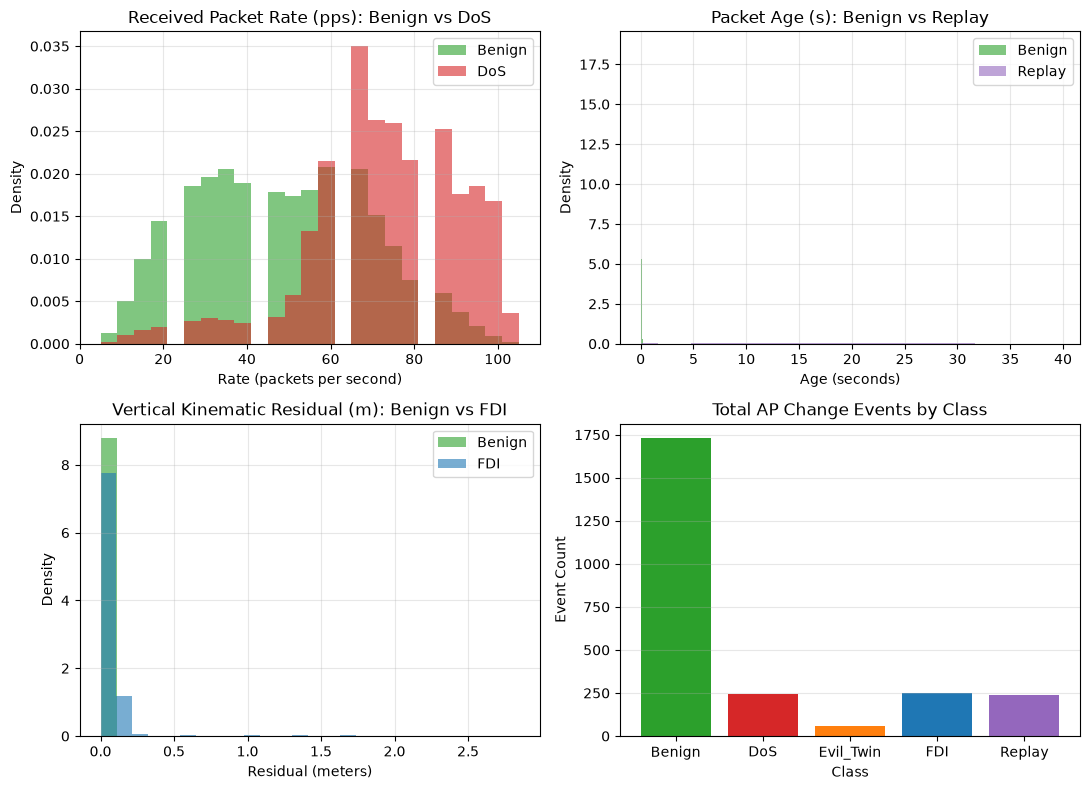

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# 1. Received packet rate
classes = ['Benign', 'DoS', 'Replay', 'Evil_Twin', 'FDI']
colors = {'Benign': '#2ca02c', 'DoS': '#d62728', 'Replay': '#9467bd', 'Evil_Twin': '#ff7f0e', 'FDI': '#1f77b4'}

for cls in ['Benign', 'DoS']:
    subset = delivered_df[delivered_df['Target_Label'] == cls]['received_rate_pps'].dropna()
    axes[0, 0].hist(subset, bins=25, alpha=0.6, label=cls, color=colors[cls], density=True)
axes[0, 0].set_title('Received Packet Rate (pps): Benign vs DoS')
axes[0, 0].set_xlabel('Rate (packets per second)')
axes[0, 0].set_ylabel('Density')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Packet age
for cls in ['Benign', 'Replay']:
    subset = delivered_df[delivered_df['Target_Label'] == cls]['packet_age_s'].dropna()
    axes[0, 1].hist(subset, bins=25, alpha=0.6, label=cls, color=colors[cls], density=True)
axes[0, 1].set_title('Packet Age (s): Benign vs Replay')
axes[0, 1].set_xlabel('Age (seconds)')
axes[0, 1].set_ylabel('Density')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Vertical Residual
for cls in ['Benign', 'FDI']:
    subset = delivered_df[delivered_df['Target_Label'] == cls]['vertical_residual_m'].dropna()
    axes[1, 0].hist(subset, bins=25, alpha=0.6, label=cls, color=colors[cls], density=True)
axes[1, 0].set_title('Vertical Kinematic Residual (m): Benign vs FDI')
axes[1, 0].set_xlabel('Residual (meters)')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Access Point Changes
ap_counts = delivered_df.groupby('Target_Label')['ap_changed'].sum()
axes[1, 1].bar(ap_counts.index, ap_counts.values, color=[colors[c] for c in ap_counts.index])
axes[1, 1].set_title('Total AP Change Events by Class')
axes[1, 1].set_xlabel('Class')
axes[1, 1].set_ylabel('Event Count')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusion
- **Data Completeness**: Delivered feature rows have zero missing values due to causal feature extraction, but DoS scenarios introduce substantial timeline delivery gaps (~40% of observations lost).
- **Physical and Cyber Separation**: Features cleanly capture domain-specific manifestations: kinematic residuals reveal FDI, timing/packet age identifies Replay, packet rates indicate DoS, and link management flags detect Evil_Twin.
- **Simulated Boundary**: All distributions reflect synthetic UAV simulator behavior. Operational transfer to real vehicles or SITL requires separate validation under realistic channel conditions.